### 02. Segmentasi Pelanggan dengan RFM

**Pertanyaan bisnis:**
1. *Siapa pelanggan paling bernilai, dan seberapa besar kontribusinya terhadap pendapatan?*
2. *Segmen pelanggan apa yang ada, dan segmen mana yang berisiko hilang?*

**Metode: RFM (Recency, Frequency, Monetary)**
- **Recency:** Jumlah hari sejak pelanggan terakhir berbelanja. Semakin kecil nilainya, semakin baik.
- **Frequency:** Jumlah transaksi unik yang dilakukan pelanggan.
- **Monetary:** Total pendapatan yang dihasilkan dari setiap pelanggan.

**Data yang Digunakan:**
data/processed/pelanggan.csv
Data hanya mencakup pelanggan yang memiliki ID, transaksi yang tidak dibatalkan, dan kode produk yang valid.

**Catatan:**
Transaksi yang dibatalkan sudah dipisahkan saat pembersihan data sehingga tidak mengurangi total pendapatan pelanggan. Analisis tingkat pembatalan setiap pelanggan dapat dilakukan pada pengembangan berikutnya.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.1f}".format)

DATA_PROCESSED = Path("..") / "data" / "processed"
OUT = Path("..") / "outputs"
OUT.mkdir(exist_ok=True)

pelanggan = pd.read_csv(
    DATA_PROCESSED / "pelanggan.csv",
    dtype={"Invoice": "string", "StockCode": "string", "Customer ID": "string"},
    parse_dates=["InvoiceDate"],
)
print(pelanggan.shape)
print("Pelanggan unik:", pelanggan["Customer ID"].nunique())

(776596, 9)
Pelanggan unik: 5852


**1. Hitung RFM per pelanggan**

Tanggal acuan ditetapkan satu hari setelah transaksi terakhir dalam data, agar pelanggan yang baru saja berbelanja memiliki nilai recency yang rendah.

In [2]:
tanggal_acuan = pelanggan["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Tanggal acuan:", tanggal_acuan.date())

rfm = (pelanggan.groupby("Customer ID")
       .agg(terakhir=("InvoiceDate", "max"),
            frequency=("Invoice", "nunique"),
            monetary=("revenue", "sum"))
       .reset_index()
       .rename(columns={"Customer ID": "customer_id"}))
rfm["recency"] = (tanggal_acuan - rfm["terakhir"]).dt.days
rfm = rfm.drop(columns="terakhir")

assert (rfm["recency"] >= 0).all()
assert (rfm["monetary"] > 0).all()
rfm.describe()

Tanggal acuan: 2011-12-10


,frequency,monetary,recency
count,"5,852.0","5,852.0","5,852.0"
mean,6.3,"2,916.7",199.7
std,12.7,"14,306.9",208.5
min,1.0,3.0,0.0
25%,1.0,339.6,25.0
50%,3.0,856.0,95.0
75%,7.0,"2,241.0",379.0
max,373.0,"580,987.0",738.0


**2. Seberapa terkonsentrasi pendapatannya?**

Sebagian besar pendapatan biasanya berasal dari sedikit pelanggan yang berbelanja dalam jumlah besar.

In [3]:
urut = rfm.sort_values("monetary", ascending=False)
total = urut["monetary"].sum()
for persen in (0.01, 0.05, 0.20):
    n = max(1, int(len(urut) * persen))
    porsi = urut["monetary"].head(n).sum() / total
    print(f"{persen:.0%} pelanggan teratas ({n:,} pelanggan) menyumbang {porsi:.1%} pendapatan")

print()
print("Frequency: pelanggan yang hanya membeli sekali:",
      f"{(rfm['frequency'] == 1).mean():.1%}")

1% pelanggan teratas (58 pelanggan) menyumbang 31.9% pendapatan
5% pelanggan teratas (292 pelanggan) menyumbang 51.9% pendapatan
20% pelanggan teratas (1,170 pelanggan) menyumbang 77.2% pendapatan

Frequency: pelanggan yang hanya membeli sekali: 27.6%


**3. Menentukan Skor dengan Skala 1–5**

Skor dibagi menjadi lima kelompok berdasarkan nilai RFM. Pelanggan dengan nilai yang sama akan mendapat skor yang sama agar hasilnya adil dan tidak bergantung pada urutan data.

- **Skor R dibalik:** Semakin baru pelanggan berbelanja, semakin tinggi skornya.
- **Ukuran kelompok bisa berbeda:** Jika banyak pelanggan memiliki nilai yang sama, jumlah pelanggan di setiap kelompok tidak harus seimbang. Akibatnya, beberapa skor bisa saja tidak terisi. Hal ini wajar.

In [4]:
def skor_kuintil(seri, terbalik=False):
    batas = seri.quantile([0.2, 0.4, 0.6, 0.8]).to_numpy()
    skor = np.digitize(seri, batas, right=True) + 1   # 1 sampai 5
    return 6 - skor if terbalik else skor

rfm["R"] = skor_kuintil(rfm["recency"], terbalik=True)
rfm["F"] = skor_kuintil(rfm["frequency"])
rfm["M"] = skor_kuintil(rfm["monetary"])

for k in ("R", "F", "M"):
    assert rfm[k].between(1, 5).all()
    print(k, rfm[k].value_counts().sort_index().to_dict())

R {1: 1168, 2: 1171, 3: 1163, 4: 1135, 5: 1215}
F {1: 1618, 2: 945, 3: 1148, 4: 1025, 5: 1116}
M {1: 1171, 2: 1170, 3: 1170, 4: 1170, 5: 1171}


**4. Menentukan Segmen Pelanggan**

Pelanggan dikelompokkan berdasarkan skor Recency (R) dan Frequency (F), sedangkan nilai belanja digunakan sebagai informasi tambahan.
- **Pelanggan terbaik:** Baru berbelanja dan sering melakukan transaksi.
- **Setia:** Cukup aktif dan cukup sering berbelanja.
- **Baru atau potensial:** Baru berbelanja, tetapi belum sering melakukan transaksi.
- **Berisiko:** Sebelumnya sering berbelanja, tetapi sudah lama tidak kembali.
- **Hilang:** Sudah lama tidak berbelanja dan jarang melakukan transaksi.
- **Perlu perhatian:** Mulai jarang berbelanja dan perlu diperhatikan agar tidak berhenti membeli.

In [5]:
kondisi = [
    (rfm["R"] >= 4) & (rfm["F"] == 5),  
    (rfm["R"] >= 3) & (rfm["F"] >= 3),
    (rfm["R"] >= 4) & (rfm["F"] <= 2),
    (rfm["R"] <= 2) & (rfm["F"] >= 3),
    (rfm["R"] <= 2) & (rfm["F"] <= 2)
]
nama = ["Pelanggan terbaik", "Setia", "Baru atau potensial", "Berisiko", "Hilang"]
rfm["segmen"] = np.select(kondisi, nama, default="Perlu perhatian")

assert rfm["segmen"].notna().all()
assert rfm["segmen"].value_counts().sum() == len(rfm)
rfm["segmen"].value_counts()

segmen
Setia                  1713
Hilang                 1630
Pelanggan terbaik       867
Berisiko                709
Baru atau potensial     512
Perlu perhatian         421
Name: count, dtype: int64

**5. Profil tiap segmen**

In [6]:
ringkasan = (rfm.groupby("segmen")
             .agg(pelanggan=("customer_id", "size"),
                  pendapatan=("monetary", "sum"),
                  recency_median=("recency", "median"),
                  frequency_median=("frequency", "median"),
                  monetary_median=("monetary", "median"))
             .assign(persen_pelanggan=lambda d: d["pelanggan"] / d["pelanggan"].sum() * 100,
                     persen_pendapatan=lambda d: d["pendapatan"] / d["pendapatan"].sum() * 100)
             .sort_values("pendapatan", ascending=False)
             .round(1))
ringkasan

,pelanggan,pendapatan,recency_median,frequency_median,monetary_median,persen_pelanggan,persen_pendapatan
segmen,,,,,,,
Pelanggan terbaik,867,"10,461,297.3",12.0,15.0,"5,425.6",14.8,61.3
Setia,1713,"3,719,398.8",49.0,5.0,"1,444.8",29.3,21.8
Berisiko,709,"1,524,847.6",366.0,4.0,"1,153.9",12.1,8.9
Hilang,1630,"690,823.6",430.0,1.0,292.3,27.9,4.0
Baru atau potensial,512,"443,212.6",25.0,2.0,382.1,8.7,2.6
Perlu perhatian,421,"229,002.9",95.0,1.0,375.1,7.2,1.3


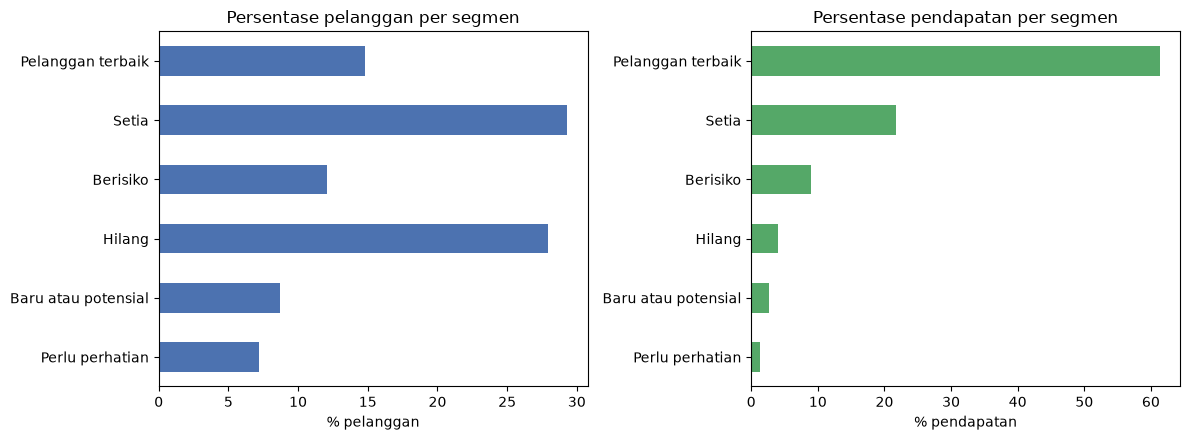

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
urutan = ringkasan.index.tolist()

ringkasan["persen_pelanggan"].plot.barh(ax=ax[0], color="#4c72b0")
ax[0].set_title("Persentase pelanggan per segmen")
ax[0].set_xlabel("% pelanggan")

ringkasan["persen_pendapatan"].plot.barh(ax=ax[1], color="#55a868")
ax[1].set_title("Persentase pendapatan per segmen")
ax[1].set_xlabel("% pendapatan")

for a in ax:
    a.invert_yaxis()
    a.set_ylabel("")
plt.tight_layout()
fig.savefig(OUT / "rfm_segmen.png", dpi=150)
plt.show()

**6. Temuan**

- **Temuan 1:** 

    Pendapatan didominasi oleh sebagian kecil pelanggan. Sebanyak 1% pelanggan teratas (58 pelanggan) menyumbang 31,9% pendapatan, sedangkan 20% teratas menyumbang 77,2%. Segmen **Pelanggan terbaik** menyumbang 61,3% pendapatan. Jika digabung dengan segmen **Setia**, keduanya mencakup 44,1% pelanggan dan menghasilkan 83,1% pendapatan.

- **Temuan 2:** [Tambahkan temuan dari hasil analisis.]

- **Temuan 3:** [Tambahkan temuan dari hasil analisis.]

**Keterbatasan:**

Analisis hanya mencakup pelanggan yang memiliki ID dari satu toko grosir hadiah di Inggris pada periode 2009–2011. Aturan pengelompokan pelanggan dibuat berdasarkan keputusan analis, sehingga hasil segmen dapat berbeda jika aturan yang digunakan berubah.

**7. Simpan hasil untuk dashboard**

In [8]:
rfm.to_csv(OUT / "rfm_pelanggan.csv", index=False)
ringkasan.reset_index().to_csv(OUT / "rfm_ringkasan_segmen.csv", index=False)
print("Tersimpan di:", OUT.resolve())
print(sorted(p.name for p in OUT.iterdir()))

Tersimpan di: C:\Users\sarah\Documents\online-retail-customer-analysis\outputs
['README_online_retail.md', 'kohort_retensi.csv', 'kohort_retensi_rata2.csv', 'retensi_heatmap.png', 'retensi_kurva.png', 'rfm_pelanggan.csv', 'rfm_ringkasan_segmen.csv', 'rfm_segmen.png']


In [29]:
kandidat = {
    "Sekarang: R>=4 & F>=4": (rfm["R"] >= 4) & (rfm["F"] >= 4),
    "A: R>=4 & F>=4 & M>=4": (rfm["R"] >= 4) & (rfm["F"] >= 4) & (rfm["M"] >= 4),
    "B: R>=4 & F=5": (rfm["R"] >= 4) & (rfm["F"] == 5),
    "C: R=5 & F>=4": (rfm["R"] == 5) & (rfm["F"] >= 4),
    "D: R=5 & F=5": (rfm["R"] == 5) & (rfm["F"] == 5),
}

total_rev = rfm["monetary"].sum()
tabel = pd.DataFrame({
    nama: {"pelanggan": int(m.sum()),
           "% pelanggan": m.mean() * 100,
           "% pendapatan": rfm.loc[m, "monetary"].sum() / total_rev * 100}
    for nama, m in kandidat.items()
}).T
tabel["pelanggan"] = tabel["pelanggan"].astype(int)
tabel.round(1)

,pelanggan,% pelanggan,% pendapatan
Sekarang: R>=4 & F>=4,1395,23.8,68.6
A: R>=4 & F>=4 & M>=4,1258,21.5,67.9
B: R>=4 & F=5,867,14.8,61.3
C: R=5 & F>=4,823,14.1,51.8
D: R=5 & F=5,564,9.6,48.4
